# 06 - Kaggle training runs

**Goal:** prove the training of every compared model (5 detectors, 6 classifiers) on Kaggle:
for each one, the Optuna trials and search space, the training curve, the PR/F1 curves or the
confusion matrix, the duration and the GPU. Everything is read from the MLflow runs created by
`import_kaggle` (experiment `tujya-vision`); nothing is downloaded from Kaggle.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import json
import tempfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

In [2]:
import mlflow

from src.utils import mlflow_utils as mu

mu.configure()  # tracking server of docker compose (http://127.0.0.1:5000), read only here
client = mlflow.MlflowClient()
TMP = Path(tempfile.mkdtemp(prefix="tujya-nb-"))  # downloaded artefacts stay outside the repo


def artefact(run_id, path):
    """Download one artefact of a run into a temporary folder and return its local path."""
    return Path(
        mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path=path, dst_path=str(TMP))
    )


def champion(model):
    mv = client.get_model_version_by_alias(model, "champion")
    return mv.run_id, mv.version

In [3]:
import yaml

SUMMARIES = sorted((ROOT / "models" / "compare").glob("*.json"))
MODELS = [p for p in SUMMARIES if p.stem.startswith(("detector_", "classifier_"))]
summary_rows = []


def report(path):
    meta = json.loads(path.read_text(encoding="utf-8"))
    run = client.get_run(meta["run_id"])
    p, m, t = run.data.params, run.data.metrics, run.data.tags
    task = t["task"]
    config = yaml.safe_load(
        artefact(run.info.run_id, "export/config.yaml").read_text(encoding="utf-8")
    )
    trials = pd.read_csv(artefact(run.info.run_id, "export/trials.csv"))
    metric = "test_v2_mAP50_95" if task == "detect" else "test_v2_top1"
    display(
        Markdown(
            f"## {t['arch']} ({task})\n\nRun `{run.info.run_id[:8]}`, branch "
            f"`{t['git_branch']}`, GPU **{t['env_gpu']}**, search {m['search_minutes']:.0f} min "
            f"+ final training {m['train_minutes']:.0f} min."
        )
    )
    space = config["search"]["space"]
    display(
        pd.DataFrame(
            [
                {
                    "parameter": k,
                    **{x: v.get(x) for x in ("type", "low", "high", "log", "choices", "ranges")},
                }
                for k, v in space.items()
            ]
        ).fillna("")
    )
    best = int(p["search_best_trial"])
    print(
        f"Optuna: {len(trials)} trials ({p['search_sampler']}), metric {p['search_metric']}, "
        f"best trial {best}: {trials.loc[trials.number == best, 'value'].iloc[0]:.4f}"
    )
    curve = pd.read_csv(artefact(run.info.run_id, "training/results.csv"))
    curve.columns = [c.strip() for c in curve.columns]
    _, axes = plt.subplots(1, 2, figsize=(9, 2.6))
    axes[0].plot(trials.number, trials.value, "o-", color="#2a78d6", markersize=3)
    axes[0].set_title("Optuna trials", fontsize=9)
    axes[0].set_xlabel("trial")
    axes[0].set_ylabel(p["search_metric"])
    y = next(
        c
        for c in ("metrics/mAP50-95(B)", "val_mAP50_95", "val_top1", "metrics/accuracy_top1")
        if c in curve
    )
    axes[1].plot(range(1, len(curve) + 1), curve[y], color="#eb6834")
    axes[1].set_title(f"final training: {y}", fontsize=9)
    axes[1].set_xlabel("epoch")
    plt.tight_layout()
    plt.show()
    image = "training/BoxPR_curve.png" if task == "detect" else "confusion/confusion_test_v2.png"
    names = {f.path for f in client.list_artifacts(run.info.run_id, image.rsplit("/", 1)[0])}
    if image in names:
        show_image(artefact(run.info.run_id, image), image, width=380)
    model = "tujya-pill-detector" if task == "detect" else "tujya-pill-classifier"
    status = client.get_model_version(model, meta["version"]).tags.get("status", "")
    summary_rows.append(
        {
            "model": t["arch"],
            "task": task,
            "trials": len(trials),
            "best_trial": best,
            "search_min": round(m["search_minutes"]),
            "train_min": round(m["train_minutes"]),
            "gpu": t["env_gpu"],
            "main_metric": metric,
            "value": f"{m[metric]:.4f}",
            "run_id": run.info.run_id[:8],
            "registry": f"v{meta['version']} {status}",
        }
    )

## baseline-cnn (classify)

Run `4d756fb9`, branch `experiment/classifier-baseline-cnn`, GPU **Tesla T4**, search 57 min + final training 47 min.

,parameter,type,low,high,log,choices,ranges
0,lr,float,0.0003,0.005,True,,
1,weight_decay,float,0.0001,0.1,True,,
2,imgsz,categorical,,,,"[128, 160, 192]",
3,width,categorical,,,,"[32, 48]",
4,dropout,float,0.0,0.4,,,
5,randaugment,int,0.0,12.0,,,
6,mix_prob,float,0.0,0.6,,,
7,label_smoothing,float,0.0,0.15,,,
8,imbalance,categorical,,,,"[none, class_weights, focal]",


Optuna: 14 trials (tpe), metric val_top1, best trial 13: 0.1287


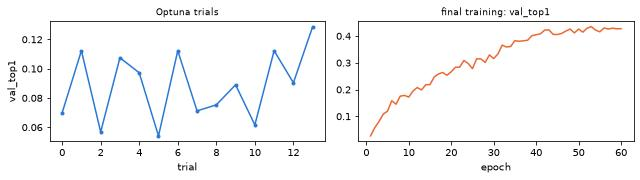

*confusion/confusion_test_v2.png*

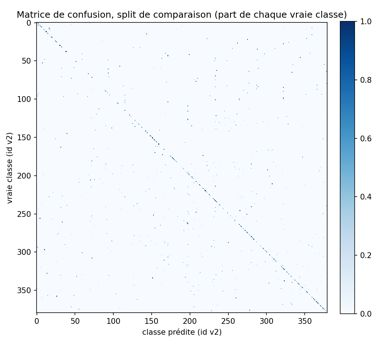

In [4]:
report(MODELS[0])

## convnext-tiny (classify)

Run `8d2dac1f`, branch `experiment/classifier-convnext-tiny`, GPU **Tesla T4**, search 63 min + final training 50 min.

,parameter,type,low,high,log,choices,ranges
0,lr,float,0.0001,0.002,True,,
1,backbone_lr_mult,float,0.03,0.5,True,,
2,weight_decay,float,0.0001,0.1,True,,
3,unfreeze,categorical,,,,"[2, 4, 6, 8]",
4,imgsz,categorical,,,,"[192, 224]",
5,randaugment,int,0.0,12.0,,,
6,mix_prob,float,0.0,0.6,,,
7,label_smoothing,float,0.0,0.15,,,
8,imbalance,categorical,,,,"[none, class_weights, focal]",


Optuna: 14 trials (tpe), metric val_top1, best trial 11: 0.8344


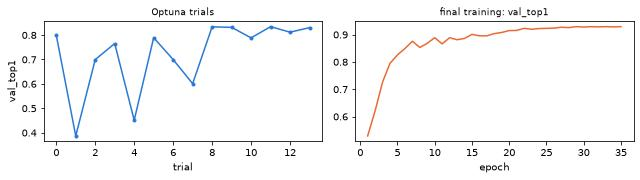

*confusion/confusion_test_v2.png*

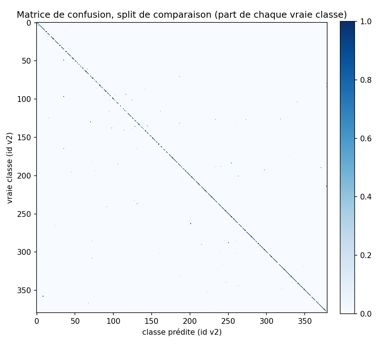

In [5]:
report(MODELS[1])

## efficientnetv2s (classify)

Run `f1ed9edd`, branch `experiment/classifier-efficientnetv2s`, GPU **Tesla T4**, search 55 min + final training 56 min.

,parameter,type,low,high,log,choices,ranges
0,lr,float,0.0001,0.003,True,,
1,backbone_lr_mult,float,0.03,0.5,True,,
2,weight_decay,float,0.0001,0.1,True,,
3,unfreeze,categorical,,,,"[2, 4, 6, 8]",
4,imgsz,categorical,,,,"[192, 224]",
5,randaugment,int,0.0,12.0,,,
6,mix_prob,float,0.0,0.6,,,
7,label_smoothing,float,0.0,0.15,,,
8,imbalance,categorical,,,,"[none, class_weights, focal]",


Optuna: 14 trials (tpe), metric val_top1, best trial 13: 0.8474


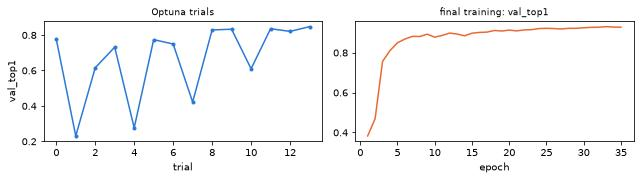

*confusion/confusion_test_v2.png*

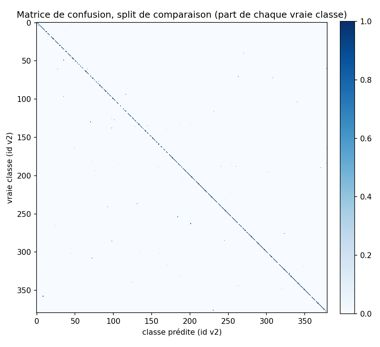

In [6]:
report(MODELS[2])

## resnet50 (classify)

Run `a53eb8fa`, branch `experiment/classifier-resnet50`, GPU **Tesla T4**, search 67 min + final training 47 min.

,parameter,type,low,high,log,choices,ranges
0,lr,float,0.0001,0.003,True,,
1,backbone_lr_mult,float,0.03,0.5,True,,
2,weight_decay,float,0.0001,0.1,True,,
3,unfreeze,categorical,,,,"[1, 2, 3, 5]",
4,imgsz,categorical,,,,"[192, 224]",
5,randaugment,int,0.0,12.0,,,
6,mix_prob,float,0.0,0.6,,,
7,label_smoothing,float,0.0,0.15,,,
8,imbalance,categorical,,,,"[none, class_weights, focal]",


Optuna: 16 trials (tpe), metric val_top1, best trial 8: 0.8186


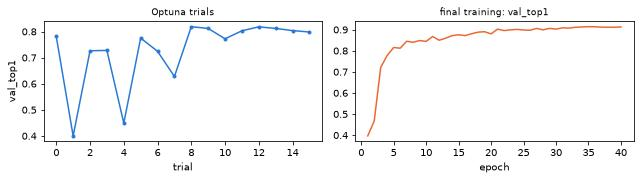

*confusion/confusion_test_v2.png*

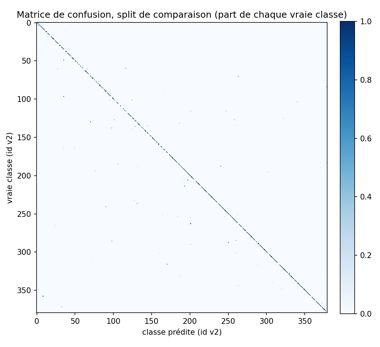

In [7]:
report(MODELS[3])

## vit-b16 (classify)

Run `64a5682a`, branch `experiment/classifier-vit-b16`, GPU **Tesla T4**, search 76 min + final training 76 min.

,parameter,type,low,high,log,choices,ranges
0,lr,float,0.00005,0.001,True,,
1,backbone_lr_mult,float,0.03,0.5,True,,
2,weight_decay,float,0.0001,0.1,True,,
3,unfreeze,categorical,,,,"[2, 4, 8, 13]",
4,randaugment,int,0.0,12.0,,,
5,mix_prob,float,0.0,0.6,,,
6,label_smoothing,float,0.0,0.15,,,
7,imbalance,categorical,,,,"[none, class_weights, focal]",


Optuna: 12 trials (tpe), metric val_top1, best trial 7: 0.7885


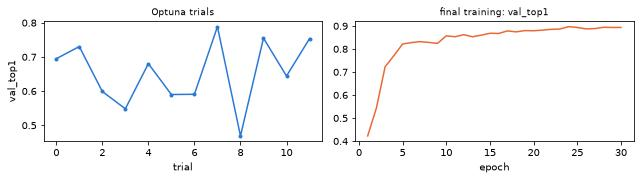

*confusion/confusion_test_v2.png*

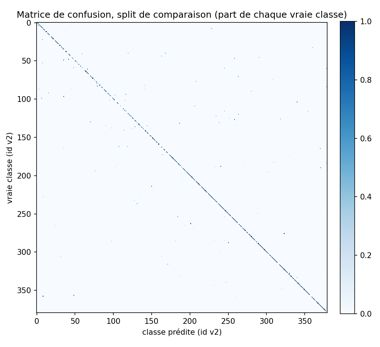

In [8]:
report(MODELS[4])

## yolo11s-cls (classify)

Run `9c8b058d`, branch `experiment/classifier-yolo11s-cls`, GPU **Tesla T4**, search 41 min + final training 26 min.

,parameter,type,low,high,log,choices,ranges
0,lr,float,0.0001,0.003,True,,
1,backbone_lr_mult,float,0.03,0.5,True,,
2,weight_decay,float,0.0001,0.1,True,,
3,unfreeze,categorical,,,,"[3, 5, 7, 10]",
4,imgsz,categorical,,,,"[192, 224]",
5,randaugment,int,0.0,12.0,,,
6,mix_prob,float,0.0,0.6,,,
7,label_smoothing,float,0.0,0.15,,,
8,imbalance,categorical,,,,"[none, class_weights, focal]",


Optuna: 16 trials (tpe), metric val_top1, best trial 8: 0.7871


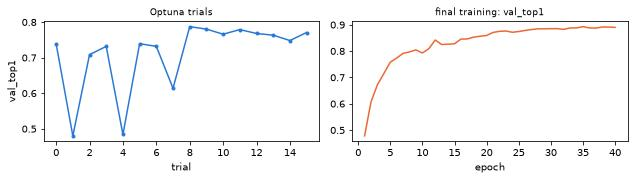

*confusion/confusion_test_v2.png*

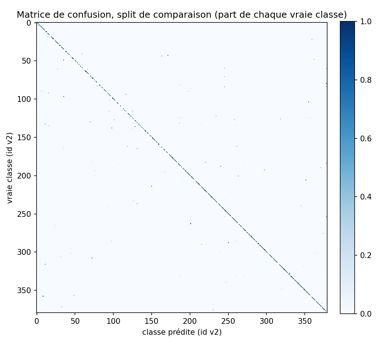

In [9]:
report(MODELS[5])

## fasterrcnn (detect)

Run `96b290a7`, branch `experiment/detector-fasterrcnn`, GPU **Tesla T4**, search 69 min + final training 94 min.

,parameter,type,low,high,log,choices,ranges
0,optimizer,categorical,,,,"[SGD, AdamW]",
1,lr0,float,,,True,,"{'SGD': [0.002, 0.04], 'AdamW': [1e-05, 0.0003]}"
2,imgsz,categorical,,,,"[480, 640]",
3,batch,categorical,,,,"[2, 4, 8]",
4,hsv_h,float,0.0,0.03,,,
5,hsv_s,float,0.2,0.9,,,
6,hsv_v,float,0.1,0.6,,,
7,fliplr,float,0.0,0.5,,,
8,flipud,float,0.0,0.5,,,


Optuna: 8 trials (tpe), metric val_mAP50_95, best trial 0: 0.7454


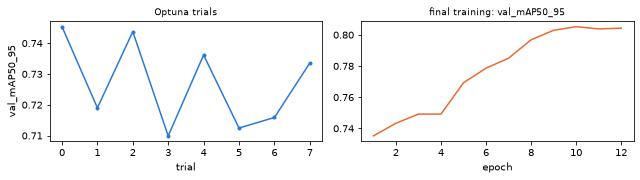

In [10]:
report(MODELS[6])

## yolo11s (detect)

Run `894871cd`, branch `experiment/detector-yolo11s`, GPU **Tesla T4**, search 76 min + final training 117 min.

,parameter,type,low,high,log,choices,ranges
0,optimizer,categorical,,,,"[SGD, AdamW]",
1,lr0,float,,,True,,"{'SGD': [0.001, 0.02], 'AdamW': [0.0001, 0.002]}"
2,imgsz,categorical,,,,"[480, 640]",
3,batch,categorical,,,,"[8, 16, 32]",
4,mosaic,float,0.0,1.0,,,
5,mixup,float,0.0,0.3,,,
6,hsv_h,float,0.0,0.03,,,
7,hsv_s,float,0.2,0.9,,,
8,hsv_v,float,0.1,0.6,,,
9,fliplr,float,0.0,0.5,,,


Optuna: 10 trials (tpe), metric val_mAP50_95, best trial 6: 0.8043


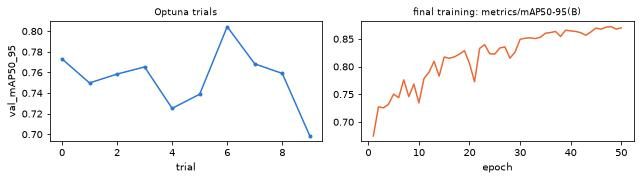

*training/BoxPR_curve.png*

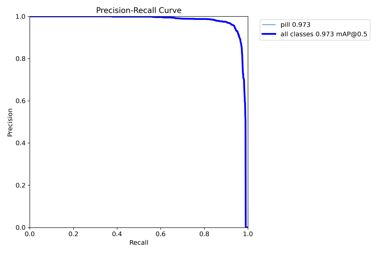

In [11]:
report(MODELS[7])

## yolov10n (detect)

Run `d28c1056`, branch `experiment/detector-yolov10n`, GPU **Tesla T4**, search 82 min + final training 98 min.

,parameter,type,low,high,log,choices,ranges
0,optimizer,categorical,,,,"[SGD, AdamW]",
1,lr0,float,,,True,,"{'SGD': [0.001, 0.02], 'AdamW': [0.0001, 0.002]}"
2,imgsz,categorical,,,,"[480, 640]",
3,batch,categorical,,,,"[8, 16, 32]",
4,mosaic,float,0.0,1.0,,,
5,mixup,float,0.0,0.3,,,
6,hsv_h,float,0.0,0.03,,,
7,hsv_s,float,0.2,0.9,,,
8,hsv_v,float,0.1,0.6,,,
9,fliplr,float,0.0,0.5,,,


Optuna: 12 trials (tpe), metric val_mAP50_95, best trial 11: 0.7855


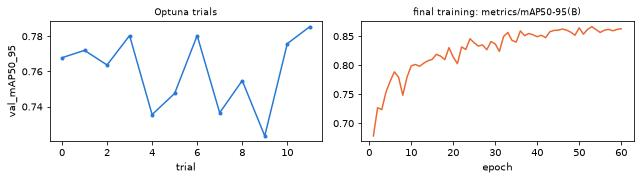

*training/BoxPR_curve.png*

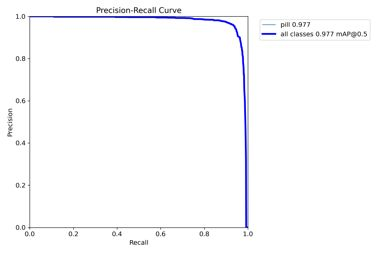

In [12]:
report(MODELS[8])

## yolov8n (detect)

Run `b0689536`, branch `experiment/detector-yolov8n`, GPU **Tesla T4**, search 68 min + final training 89 min.

,parameter,type,low,high,log,choices,ranges
0,optimizer,categorical,,,,"[SGD, AdamW]",
1,lr0,float,,,True,,"{'SGD': [0.001, 0.02], 'AdamW': [0.0001, 0.002]}"
2,imgsz,categorical,,,,"[480, 640]",
3,batch,categorical,,,,"[8, 16, 32]",
4,mosaic,float,0.0,1.0,,,
5,mixup,float,0.0,0.3,,,
6,hsv_h,float,0.0,0.03,,,
7,hsv_s,float,0.2,0.9,,,
8,hsv_v,float,0.1,0.6,,,
9,fliplr,float,0.0,0.5,,,


Optuna: 12 trials (tpe), metric val_mAP50_95, best trial 11: 0.7900


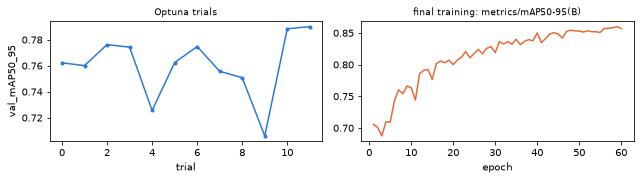

*training/BoxPR_curve.png*

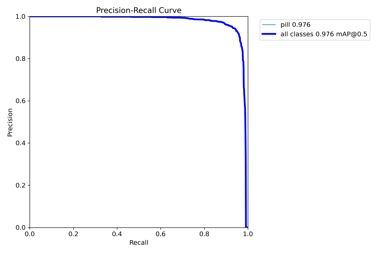

In [13]:
report(MODELS[9])

## yolov8s (detect)

Run `e4d25272`, branch `experiment/detector-yolov8s`, GPU **Tesla T4**, search 58 min + final training 82 min.

,parameter,type,low,high,log,choices,ranges
0,optimizer,categorical,,,,"[SGD, AdamW]",
1,lr0,float,,,True,,"{'SGD': [0.001, 0.02], 'AdamW': [0.0001, 0.002]}"
2,imgsz,categorical,,,,"[480, 640]",
3,batch,categorical,,,,"[8, 16, 32]",
4,mosaic,float,0.0,1.0,,,
5,mixup,float,0.0,0.3,,,
6,hsv_h,float,0.0,0.03,,,
7,hsv_s,float,0.2,0.9,,,
8,hsv_v,float,0.1,0.6,,,
9,fliplr,float,0.0,0.5,,,


Optuna: 10 trials (tpe), metric val_mAP50_95, best trial 6: 0.7937


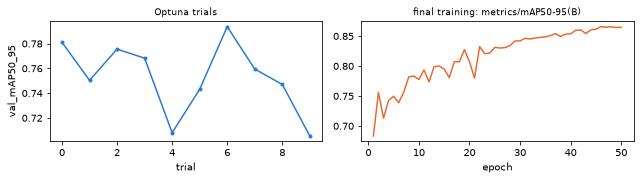

*training/BoxPR_curve.png*

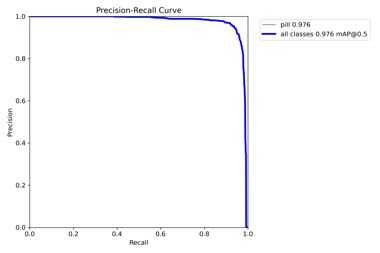

In [14]:
report(MODELS[10])

## Summary

In [15]:
pd.DataFrame(summary_rows)

,model,task,trials,best_trial,search_min,train_min,gpu,main_metric,value,run_id,registry
0,baseline-cnn,classify,14,13,57,47,Tesla T4,test_v2_top1,0.3669,4d756fb9,v13 archived
1,convnext-tiny,classify,14,11,63,50,Tesla T4,test_v2_top1,0.8966,8d2dac1f,v10 archived
2,efficientnetv2s,classify,14,13,55,56,Tesla T4,test_v2_top1,0.9089,f1ed9edd,v8 champion
3,resnet50,classify,16,8,67,47,Tesla T4,test_v2_top1,0.9027,a53eb8fa,v9 challenger
4,vit-b16,classify,12,7,76,76,Tesla T4,test_v2_top1,0.8515,64a5682a,v12 archived
5,yolo11s-cls,classify,16,8,41,26,Tesla T4,test_v2_top1,0.8594,9c8b058d,v11 archived
6,fasterrcnn,detect,8,0,69,94,Tesla T4,test_v2_mAP50_95,0.8218,96b290a7,v12 archived
7,yolo11s,detect,10,6,76,117,Tesla T4,test_v2_mAP50_95,0.8885,894871cd,v9 champion
8,yolov10n,detect,12,11,82,98,Tesla T4,test_v2_mAP50_95,0.8860,d28c1056,v10 challenger
9,yolov8n,detect,12,11,68,89,Tesla T4,test_v2_mAP50_95,0.8774,b0689536,v2 archived
